<a href="https://colab.research.google.com/github/nilanjanajui/pyrosync/blob/main/notebooks/phase4_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip install -q pandas numpy matplotlib seaborn pyarrow scipy

import json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LogNorm, SymLogNorm
from scipy.stats import pearsonr, spearmanr, linregress
from google.colab import drive

warnings.filterwarnings("ignore")
drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/Nasa App Challenges/PyroSync")
PHASE3_DIR  = PROJECT_DIR / "data" / "aggregated" / "phase3"
EVAL_DIR    = PROJECT_DIR / "data" / "evaluation" / "phase4"
REPORT_DIR  = PROJECT_DIR / "reports" / "phase4"
for d in [EVAL_DIR, REPORT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

PANEL_PATH  = PHASE3_DIR / "panel_cell_month_2012_2021.parquet"
PAIRED_PATH = PHASE3_DIR / "paired_cell_month_2012_2021.parquet"
for p in [PANEL_PATH, PAIRED_PATH]:
    if not p.exists():
        raise FileNotFoundError(f"Run Phase 3 first: {p}")

panel  = pd.read_parquet(PANEL_PATH)
paired = pd.read_parquet(PAIRED_PATH)

NEEDED = ["ix", "iy", "cell_id", "month", "modis_all_n", "modis_all_frp", "modis_terra_n",
          "modis_aqua_n", "viirs_all_n", "viirs_all_frp", "modis_record_present",
          "viirs_record_present", "lat", "lon"]
missing = [c for c in NEEDED if c not in panel.columns]
assert not missing, f"Panel missing columns: {missing}"

panel["month"] = pd.to_datetime(panel["month"])
print("Panel rows:", f"{len(panel):,}", "| Paired rows:", f"{len(paired):,}")
print("Months:", panel["month"].nunique(), "|", panel["month"].min().date(), "to", panel["month"].max().date())

Mounted at /content/drive
Panel rows: 538,713 | Paired rows: 34,841
Months: 119 | 2012-02-01 to 2021-12-01


In [2]:
SEASON = {12: "DJF", 1: "DJF", 2: "DJF", 3: "MAM", 4: "MAM", 5: "MAM",
          6: "JJA", 7: "JJA", 8: "JJA", 9: "SON", 10: "SON", 11: "SON"}
SEASON_ORDER = ["DJF", "MAM", "JJA", "SON"]

panel["year"] = panel["month"].dt.year
panel["season"] = panel["month"].dt.month.map(SEASON)
panel["region"] = np.select([panel["lat"] < 36, panel["lat"] < 38],
                            ["South California", "Central California"], "North California")

panel["both_present"] = panel["modis_record_present"] & panel["viirs_record_present"]
panel["modis_only"]   = panel["modis_record_present"] & ~panel["viirs_record_present"]
panel["viirs_only"]   = panel["viirs_record_present"] & ~panel["modis_record_present"]

data = panel[panel["modis_record_present"] | panel["viirs_record_present"]]
assert len(data) == len(paired), "Panel and paired tables disagree"
both = panel[panel["both_present"]].copy()
assert len(both) > 0, "No cell-months with both sensors"

print("Non-empty cell-months:", f"{len(data):,}")
print("MODIS-present:", f"{panel['modis_record_present'].sum():,}",
      "| VIIRS-present:", f"{panel['viirs_record_present'].sum():,}")
print("Both:", f"{len(both):,}", "| MODIS-only:", f"{panel['modis_only'].sum():,}",
      "| VIIRS-only:", f"{panel['viirs_only'].sum():,}")

Non-empty cell-months: 34,841
MODIS-present: 15,482 | VIIRS-present: 31,545
Both: 12,186 | MODIS-only: 3,296 | VIIRS-only: 19,359


,month,modis_detections,modis_cell_months,viirs_detections,viirs_cell_months,year,viirs_per_modis
0,2012-02-01,243,147,600,239,2012,2.469136
1,2012-03-01,189,99,452,218,2012,2.391534
2,2012-04-01,117,71,369,169,2012,3.153846


,year,modis_detections,viirs_detections,months,difference,viirs_per_modis
0,2012,8888,36343,11,27455,4.089
1,2013,10273,40099,12,29826,3.903
2,2014,8288,35979,12,27691,4.341
3,2015,11524,51557,12,40033,4.474
4,2016,8789,32769,12,23980,3.728
5,2017,17644,72754,12,55110,4.123
6,2018,21240,81388,12,60148,3.832
7,2019,5573,19898,12,14325,3.570
8,2020,49827,230608,12,180781,4.628
9,2021,45271,195567,12,150296,4.320


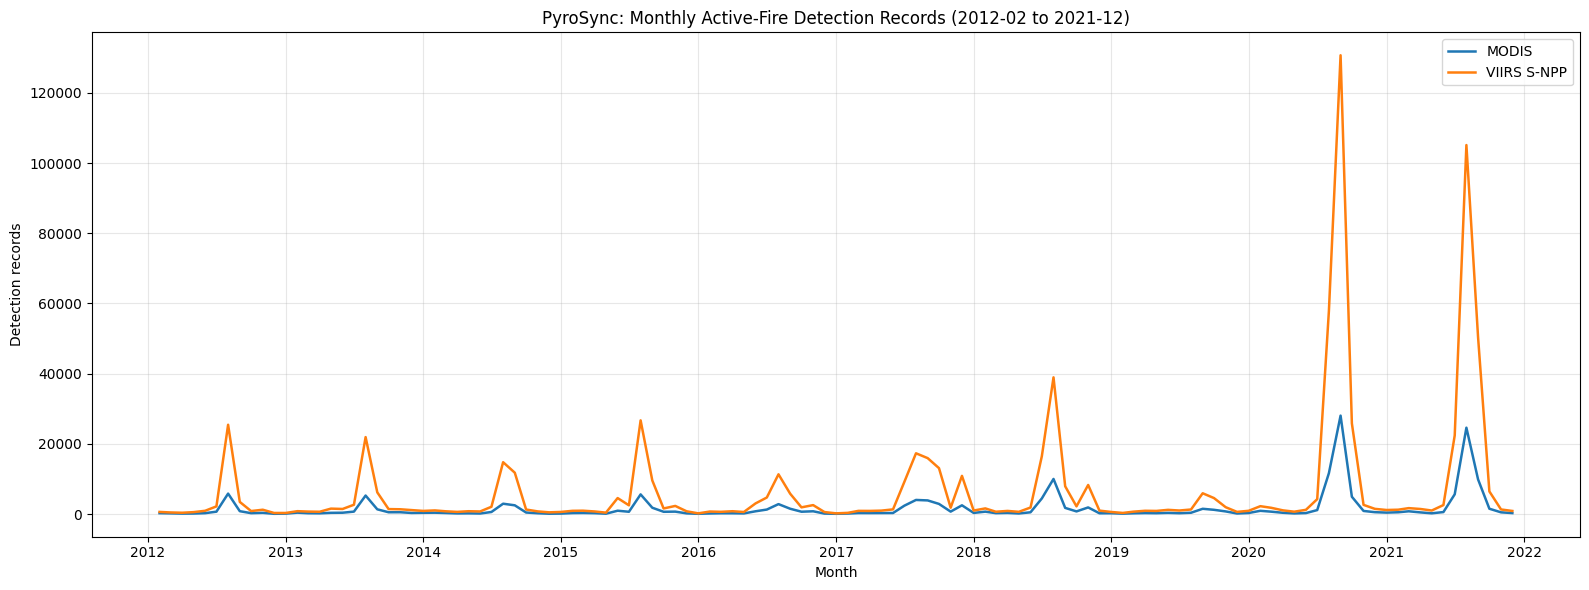

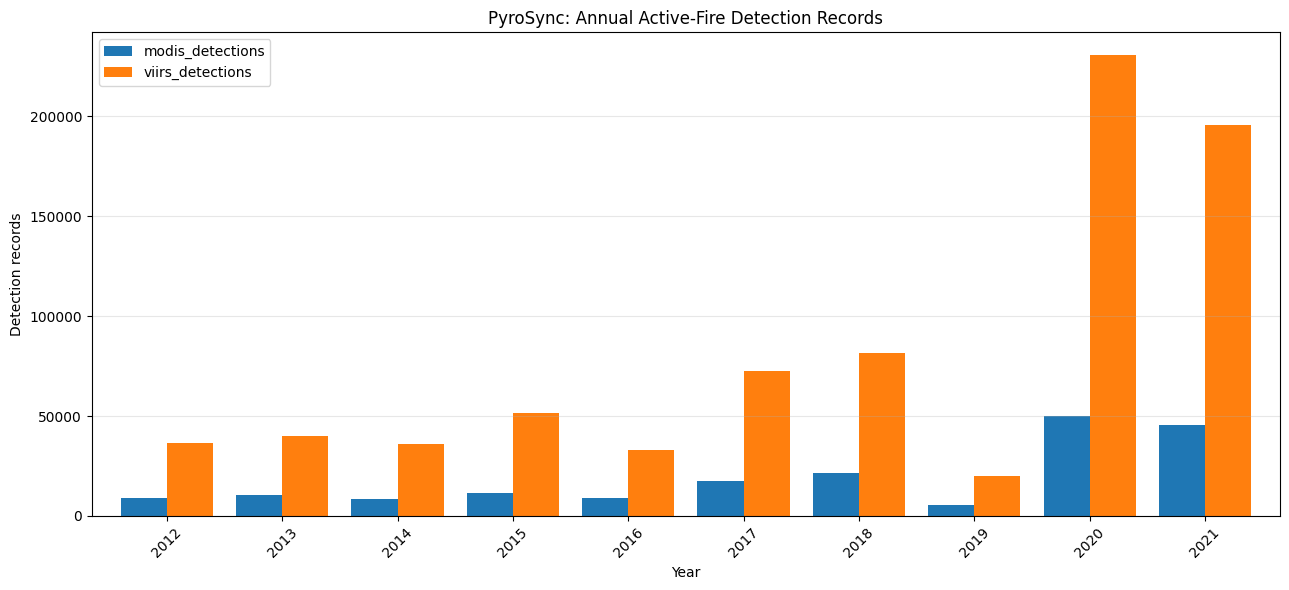

In [3]:
monthly = (panel.groupby("month")
    .agg(modis_detections=("modis_all_n", "sum"), modis_cell_months=("modis_record_present", "sum"),
         viirs_detections=("viirs_all_n", "sum"), viirs_cell_months=("viirs_record_present", "sum"))
    .reset_index())
monthly["year"] = monthly["month"].dt.year
monthly["viirs_per_modis"] = monthly["viirs_detections"] / monthly["modis_detections"]

annual = (monthly.groupby("year")
    .agg(modis_detections=("modis_detections", "sum"), viirs_detections=("viirs_detections", "sum"),
         months=("month", "count")).reset_index())
annual["difference"] = annual["viirs_detections"] - annual["modis_detections"]
annual["viirs_per_modis"] = (annual["viirs_detections"] / annual["modis_detections"]).round(3)

display(monthly.head(3))
display(annual)

plt.figure(figsize=(16, 6))
plt.plot(monthly["month"], monthly["modis_detections"], label="MODIS", linewidth=1.8)
plt.plot(monthly["month"], monthly["viirs_detections"], label="VIIRS S-NPP", linewidth=1.8)
plt.title("PyroSync: Monthly Active-Fire Detection Records (2012-02 to 2021-12)")
plt.xlabel("Month"); plt.ylabel("Detection records"); plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(REPORT_DIR / "monthly_detection_trends.png", dpi=300); plt.show()

annual.set_index("year")[["modis_detections", "viirs_detections"]].plot(kind="bar", figsize=(13, 6), width=0.8)
plt.title("PyroSync: Annual Active-Fire Detection Records"); plt.xlabel("Year")
plt.ylabel("Detection records"); plt.xticks(rotation=45); plt.grid(axis="y", alpha=0.3); plt.tight_layout()
plt.savefig(REPORT_DIR / "annual_detection_trends.png", dpi=300); plt.show()

,region,modis_detections,modis_cell_months,viirs_detections,viirs_cell_months,difference,viirs_per_modis
0,Central California,46831,4978,200935,10127,154104,4.291
1,North California,121872,7495,520893,13997,399021,4.274
2,South California,18614,3009,75134,7421,56520,4.036


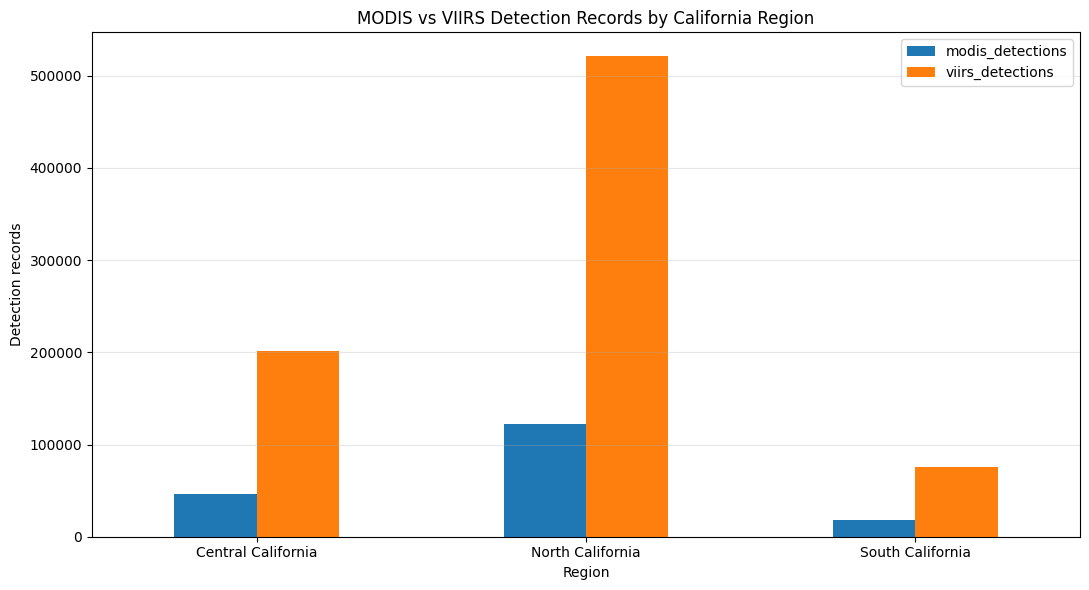

In [4]:
regional = (panel.groupby("region")
    .agg(modis_detections=("modis_all_n", "sum"), modis_cell_months=("modis_record_present", "sum"),
         viirs_detections=("viirs_all_n", "sum"), viirs_cell_months=("viirs_record_present", "sum"))
    .reset_index())
regional["difference"] = regional["viirs_detections"] - regional["modis_detections"]
regional["viirs_per_modis"] = (regional["viirs_detections"] / regional["modis_detections"]).round(3)
display(regional)

regional.set_index("region")[["modis_detections", "viirs_detections"]].plot(kind="bar", figsize=(11, 6))
plt.title("MODIS vs VIIRS Detection Records by California Region")
plt.xlabel("Region"); plt.ylabel("Detection records"); plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3); plt.tight_layout()
plt.savefig(REPORT_DIR / "regional_comparison.png", dpi=300); plt.show()

,0
paired_cell_months,12186.000000
pearson_r,0.972107
pearson_p_value,0.000000
spearman_r,0.711912
spearman_p_value,0.000000
pearson_r_log1p,0.912521
pearson_r_top1pct_removed,0.958751
regression_slope,4.426424
regression_intercept,-4.325783
regression_r_squared,0.944992


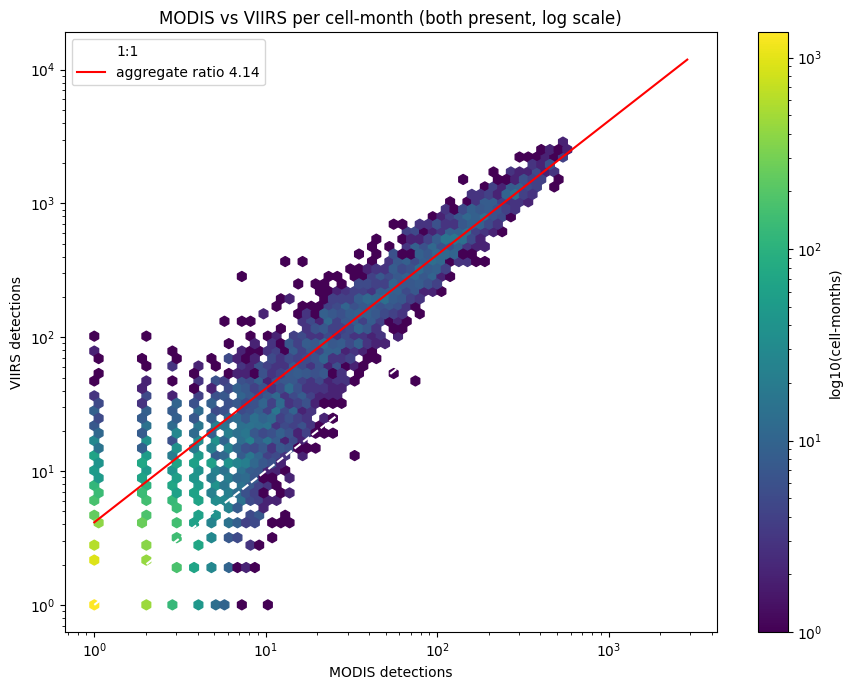

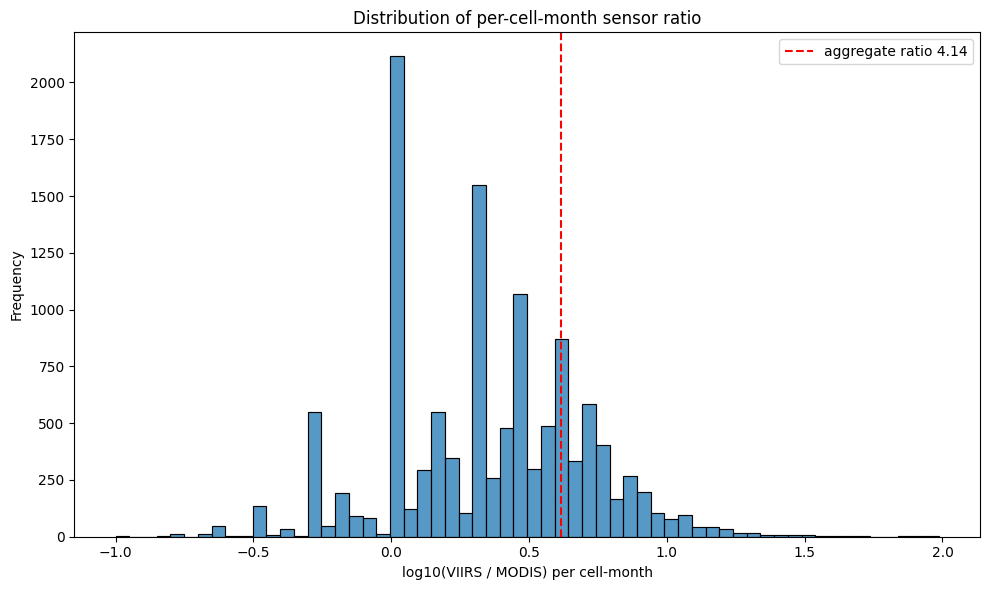

In [5]:
x = both["modis_all_n"].to_numpy(float)
y = both["viirs_all_n"].to_numpy(float)

pearson_r, pearson_p = pearsonr(x, y)
spearman_r, spearman_p = spearmanr(x, y)
reg = linregress(x, y)
pearson_log = pearsonr(np.log1p(x), np.log1p(y))[0]
keep = x <= np.quantile(x, 0.99)
pearson_trim = pearsonr(x[keep], y[keep])[0]

diff = y - x
bias, mae, rmse = diff.mean(), np.abs(diff).mean(), np.sqrt((diff ** 2).mean())
agg_ratio = y.sum() / x.sum()

correlation_results = pd.DataFrame([{
    "paired_cell_months": len(both), "pearson_r": pearson_r, "pearson_p_value": pearson_p,
    "spearman_r": spearman_r, "spearman_p_value": spearman_p,
    "pearson_r_log1p": pearson_log, "pearson_r_top1pct_removed": pearson_trim,
    "regression_slope": reg.slope, "regression_intercept": reg.intercept, "regression_r_squared": reg.rvalue ** 2,
    "aggregate_ratio_viirs_per_modis": agg_ratio,
    "mean_bias_viirs_minus_modis": bias, "mae": mae, "rmse": rmse,
}])
display(correlation_results.T)

plt.figure(figsize=(9, 7))
plt.hexbin(x, y, gridsize=55, xscale="log", yscale="log", bins="log", mincnt=1)
plt.colorbar(label="log10(cell-months)")
lim = [1, max(x.max(), y.max())]
plt.plot(lim, lim, "--", color="white", label="1:1")
plt.plot(lim, [agg_ratio * v for v in lim], color="red", label=f"aggregate ratio {agg_ratio:.2f}")
plt.xlabel("MODIS detections"); plt.ylabel("VIIRS detections")
plt.title("MODIS vs VIIRS per cell-month (both present, log scale)")
plt.legend(); plt.tight_layout(); plt.savefig(REPORT_DIR / "sensor_scatterplot.png", dpi=300); plt.show()

plt.figure(figsize=(10, 6))
sns.histplot(np.log10(y / x), bins=60)
plt.axvline(np.log10(agg_ratio), color="red", linestyle="--", label=f"aggregate ratio {agg_ratio:.2f}")
plt.xlabel("log10(VIIRS / MODIS) per cell-month"); plt.ylabel("Frequency")
plt.title("Distribution of per-cell-month sensor ratio"); plt.legend(); plt.tight_layout()
plt.savefig(REPORT_DIR / "sensor_ratio_distribution.png", dpi=300); plt.show()

By year (all cell-months):


,year,modis,terra,aqua,viirs,viirs_per_modis,viirs_per_terra,viirs_per_aqua
0,2012,8888,4279,4609,36343,4.089,8.493,7.885
1,2013,10273,5046,5227,40099,3.903,7.947,7.672
2,2014,8288,4101,4187,35979,4.341,8.773,8.593
3,2015,11524,5543,5981,51557,4.474,9.301,8.620
4,2016,8789,4411,4378,32769,3.728,7.429,7.485
5,2017,17644,8999,8645,72754,4.123,8.085,8.416
6,2018,21240,10809,10431,81388,3.832,7.530,7.803
7,2019,5573,2901,2672,19898,3.570,6.859,7.447
8,2020,49827,26433,23394,230608,4.628,8.724,9.858
9,2021,45271,22978,22293,195567,4.320,8.511,8.773


By year (both-present only):


,year,viirs_per_modis
0,2012,3.929
1,2013,3.722
2,2014,4.100
3,2015,4.237
4,2016,3.438
5,2017,3.975
6,2018,3.733
7,2019,3.098
8,2020,4.574
9,2021,4.269


By season (all cell-months):


,season,modis,terra,aqua,viirs,viirs_per_modis,viirs_per_terra,viirs_per_aqua
0,DJF,10167,4369,5798,33703,3.315,7.714,5.813
1,MAM,8048,4326,3722,25551,3.175,5.906,6.865
2,JJA,95173,49949,45224,406835,4.275,8.145,8.996
3,SON,73929,36856,37073,330873,4.476,8.977,8.925


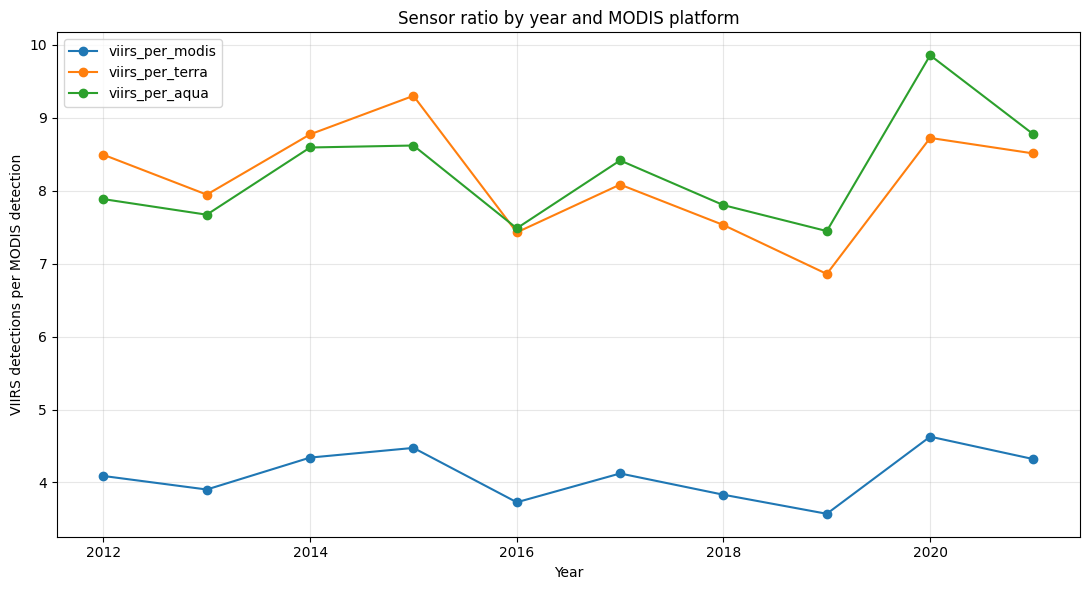

In [6]:
def ratio_table(df, by):
    g = (df.groupby(by)
         .agg(modis=("modis_all_n", "sum"), terra=("modis_terra_n", "sum"),
              aqua=("modis_aqua_n", "sum"), viirs=("viirs_all_n", "sum")).reset_index())
    g["viirs_per_modis"] = g["viirs"] / g["modis"]
    g["viirs_per_terra"] = g["viirs"] / g["terra"]
    g["viirs_per_aqua"]  = g["viirs"] / g["aqua"]
    return g

ratio_year = ratio_table(panel, "year")
ratio_year_both = ratio_table(both, "year")
ratio_season = ratio_table(panel, "season").set_index("season").loc[SEASON_ORDER].reset_index()

cols = ["viirs_per_modis", "viirs_per_terra", "viirs_per_aqua"]
print("By year (all cell-months):");  display(ratio_year.round(3))
print("By year (both-present only):"); display(ratio_year_both[["year", "viirs_per_modis"]].round(3))
print("By season (all cell-months):"); display(ratio_season.round(3))

plt.figure(figsize=(11, 6))
for c in cols:
    plt.plot(ratio_year["year"], ratio_year[c], marker="o", label=c)
plt.xlabel("Year"); plt.ylabel("VIIRS detections per MODIS detection")
plt.title("Sensor ratio by year and MODIS platform"); plt.grid(alpha=0.3); plt.legend(); plt.tight_layout()
plt.savefig(REPORT_DIR / "ratio_by_year_platform.png", dpi=300); plt.show()

Cells with any detection: 3,182


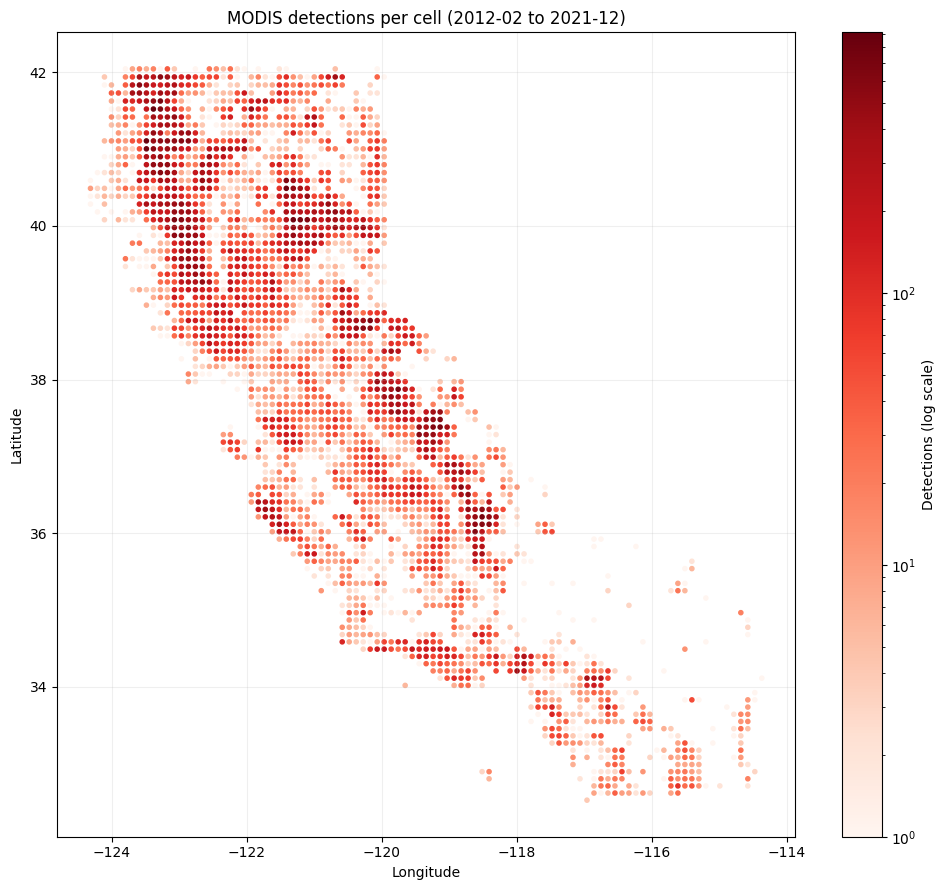

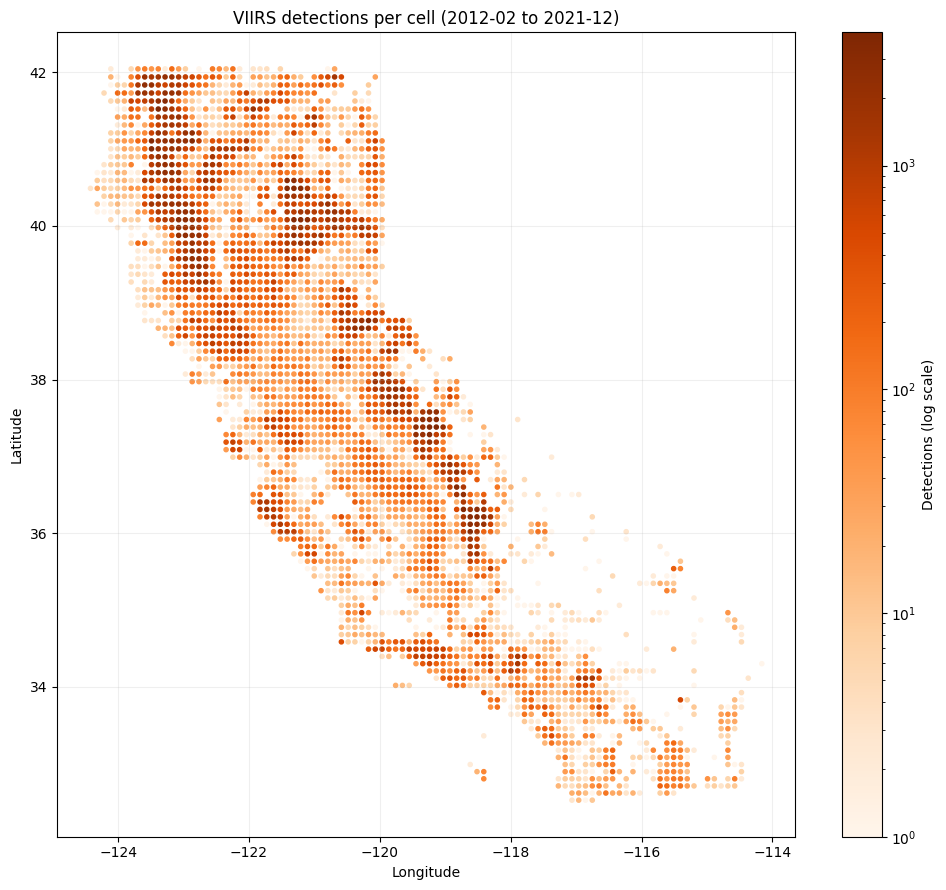

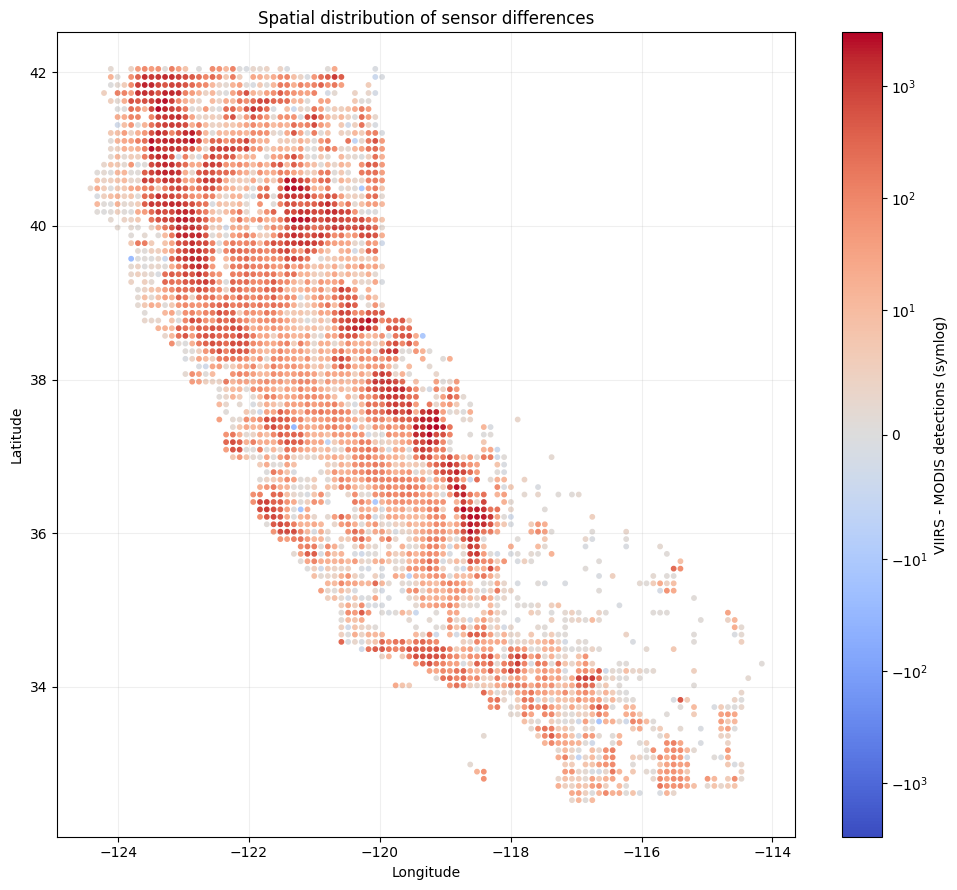


Top 10 cells by VIIRS detections:


,ix,iy,lat,lon,modis_detections,viirs_detections,difference
277,-1191,485,41.522081,-123.385418,909,3943,3034
2697,-1150,444,37.381492,-119.136109,691,3593,2902
1233,-1172,475,40.489327,-121.416226,775,3449,2674
477,-1186,481,41.107063,-122.867209,590,3344,2754
1294,-1171,471,40.080599,-121.312584,787,3343,2556
236,-1192,480,41.003712,-123.489059,786,3290,2504
2876,-1146,433,36.309192,-118.721542,495,3262,2767
237,-1192,481,41.107063,-123.489059,850,3259,2409
2832,-1147,436,36.600179,-118.825184,586,3195,2609
2648,-1151,444,37.381492,-119.239751,624,3158,2534


In [7]:
cell_totals = (panel.groupby(["ix", "iy", "lat", "lon"], as_index=False)
    .agg(modis_detections=("modis_all_n", "sum"), viirs_detections=("viirs_all_n", "sum")))
cell_totals = cell_totals[(cell_totals["modis_detections"] > 0) | (cell_totals["viirs_detections"] > 0)].copy()
cell_totals["difference"] = cell_totals["viirs_detections"] - cell_totals["modis_detections"]
print("Cells with any detection:", f"{len(cell_totals):,}")

for col, cmap, title, fname in [
    ("modis_detections", "Reds", "MODIS detections per cell (2012-02 to 2021-12)", "spatial_modis.png"),
    ("viirs_detections", "Oranges", "VIIRS detections per cell (2012-02 to 2021-12)", "spatial_viirs.png")]:
    s = cell_totals[cell_totals[col] > 0]
    plt.figure(figsize=(10, 9))
    sc = plt.scatter(s["lon"], s["lat"], c=s[col], s=9, cmap=cmap, norm=LogNorm(vmin=1))
    plt.colorbar(sc, label="Detections (log scale)")
    plt.title(title); plt.xlabel("Longitude"); plt.ylabel("Latitude"); plt.grid(alpha=0.2); plt.tight_layout()
    plt.savefig(REPORT_DIR / fname, dpi=300); plt.show()

plt.figure(figsize=(10, 9))
sc = plt.scatter(cell_totals["lon"], cell_totals["lat"], c=cell_totals["difference"], s=10, cmap="coolwarm",
                 norm=SymLogNorm(linthresh=10, vmin=-3000, vmax=3000))
plt.colorbar(sc, label="VIIRS - MODIS detections (symlog)")
plt.title("Spatial distribution of sensor differences"); plt.xlabel("Longitude"); plt.ylabel("Latitude")
plt.grid(alpha=0.2); plt.tight_layout()
plt.savefig(REPORT_DIR / "spatial_sensor_difference.png", dpi=300); plt.show()

print("\nTop 10 cells by VIIRS detections:")
display(cell_totals.nlargest(10, "viirs_detections"))

,sensor,mean_frp,median_frp,total_frp,std_frp
0,MODIS,1935.690629,45.70,23588326.00,8404.151047
1,VIIRS,1158.474991,36.97,14117176.24,4772.954711


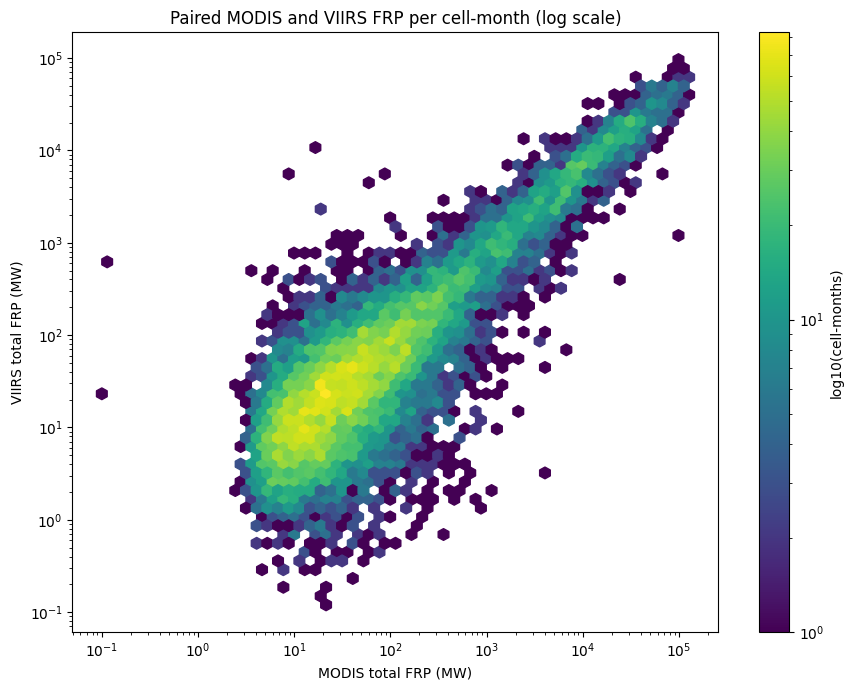

In [8]:
frp = both[["modis_all_frp", "viirs_all_frp"]]
frp_comparison = pd.DataFrame({
    "sensor": ["MODIS", "VIIRS"],
    "mean_frp":   [frp["modis_all_frp"].mean(),   frp["viirs_all_frp"].mean()],
    "median_frp": [frp["modis_all_frp"].median(), frp["viirs_all_frp"].median()],
    "total_frp":  [frp["modis_all_frp"].sum(),    frp["viirs_all_frp"].sum()],
    "std_frp":    [frp["modis_all_frp"].std(),    frp["viirs_all_frp"].std()],
})
display(frp_comparison)

plt.figure(figsize=(9, 7))
plt.hexbin(frp["modis_all_frp"].clip(lower=0.1), frp["viirs_all_frp"].clip(lower=0.1),
           gridsize=55, xscale="log", yscale="log", bins="log", mincnt=1)
plt.colorbar(label="log10(cell-months)")
plt.xlabel("MODIS total FRP (MW)"); plt.ylabel("VIIRS total FRP (MW)")
plt.title("Paired MODIS and VIIRS FRP per cell-month (log scale)"); plt.tight_layout()
plt.savefig(REPORT_DIR / "frp_comparison.png", dpi=300); plt.show()

,month,terra_detections,aqua_detections,difference
0,2012-02-01,124,119,-5
1,2012-03-01,88,101,13
2,2012-04-01,48,69,21
3,2012-05-01,63,72,9
4,2012-06-01,120,126,6


Terra total: 95,500 | Aqua total: 91,817


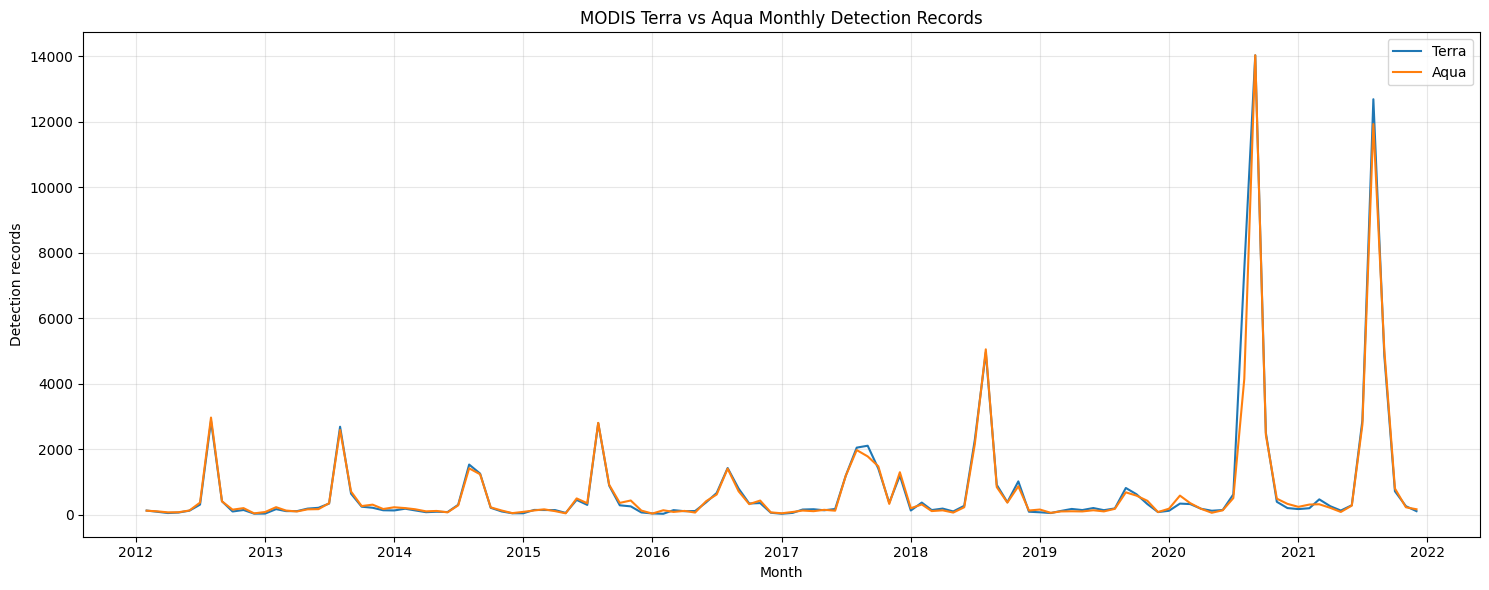

In [9]:
terra_aqua = (panel.groupby("month")
    .agg(terra_detections=("modis_terra_n", "sum"), aqua_detections=("modis_aqua_n", "sum")).reset_index())
terra_aqua["difference"] = terra_aqua["aqua_detections"] - terra_aqua["terra_detections"]
display(terra_aqua.head(5))
print("Terra total:", f"{terra_aqua['terra_detections'].sum():,}", "| Aqua total:", f"{terra_aqua['aqua_detections'].sum():,}")

plt.figure(figsize=(15, 6))
plt.plot(terra_aqua["month"], terra_aqua["terra_detections"], label="Terra")
plt.plot(terra_aqua["month"], terra_aqua["aqua_detections"], label="Aqua")
plt.title("MODIS Terra vs Aqua Monthly Detection Records"); plt.xlabel("Month"); plt.ylabel("Detection records")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(REPORT_DIR / "terra_aqua_comparison.png", dpi=300); plt.show()

In [10]:
outputs = {
    "monthly_comparison.csv": monthly, "annual_comparison.csv": annual,
    "regional_comparison.csv": regional, "correlation_analysis.csv": correlation_results,
    "spatial_agreement.csv": cell_totals, "frp_comparison.csv": frp_comparison,
    "terra_aqua_comparison.csv": terra_aqua, "ratio_by_year.csv": ratio_year,
    "ratio_by_season.csv": ratio_season,
}
for name, df in outputs.items():
    df.to_csv(EVAL_DIR / name, index=False)
    print(f"Saved {name:28} {len(df):>6,} rows")
both.to_parquet(EVAL_DIR / "both_present_comparison.parquet", index=False)

metadata = {
    "project": "PyroSync", "phase": 4, "phase_name": "Exploratory Data Analysis",
    "analysis_period": {"start": str(panel["month"].min().date()), "end": str(panel["month"].max().date())},
    "grid": "10 km, EPSG:6933",
    "input_rows": {"panel": int(len(panel)), "non_empty_cell_months": int(len(data)), "both_present": int(len(both))},
    "agreement_stats_both_present": {k: float(v) for k, v in correlation_results.iloc[0].items()},
    "limitations": [
        "Detection records are not unique fire events.",
        "Agreement statistics are conditional on both sensors detecting in the cell-month.",
        "Linear correlation is dominated by a few very large cell-months; see log and trimmed correlations.",
        "The sensor ratio varies by year and season; a constant ratio is a simplification.",
        "FRP comparisons are secondary; MODIS and VIIRS FRP are not the same quantity.",
        "Latitude-based regions are approximate analytical subdivisions.",
    ],
}
with open(EVAL_DIR / "phase4_metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)
print("Metadata saved.")

Saved monthly_comparison.csv          119 rows
Saved annual_comparison.csv            10 rows
Saved regional_comparison.csv           3 rows
Saved correlation_analysis.csv          1 rows
Saved spatial_agreement.csv         3,182 rows
Saved frp_comparison.csv                2 rows
Saved terra_aqua_comparison.csv       119 rows
Saved ratio_by_year.csv                10 rows
Saved ratio_by_season.csv               4 rows
Metadata saved.


In [11]:
print("=" * 80); print("PYROSYNC — PHASE 4 FINAL REPORT"); print("=" * 80)
print(f"\nPeriod: {panel['month'].min().date()} to {panel['month'].max().date()} ({panel['month'].nunique()} months)")
print(f"Non-empty cell-months: {len(data):,} | both: {len(both):,} | "
      f"MODIS-only: {panel['modis_only'].sum():,} | VIIRS-only: {panel['viirs_only'].sum():,}")
print("\nAnnual totals and VIIRS/MODIS ratio:"); print(annual.to_string(index=False))
print("\nRegional:"); print(regional.to_string(index=False))
print("\nAgreement (both-present rows):")
for k in ["pearson_r", "pearson_r_log1p", "pearson_r_top1pct_removed", "spearman_r",
          "regression_slope", "aggregate_ratio_viirs_per_modis", "mean_bias_viirs_minus_modis", "mae", "rmse"]:
    print(f"  {k:34} {correlation_results.iloc[0][k]:.4f}")
print("\nRatio by season:"); print(ratio_season[["season", "viirs_per_modis"]].round(3).to_string(index=False))
print("\nLimitations:"); [print("-", l) for l in metadata["limitations"]]
print("\nSaved files:")
for p in sorted(EVAL_DIR.iterdir()):
    if p.is_file(): print(f"  {p.name:36} {p.stat().st_size/(1024**2):8.3f} MB")
print("\nPHASE 4 COMPLETED")

PYROSYNC — PHASE 4 FINAL REPORT

Period: 2012-02-01 to 2021-12-01 (119 months)
Non-empty cell-months: 34,841 | both: 12,186 | MODIS-only: 3,296 | VIIRS-only: 19,359

Annual totals and VIIRS/MODIS ratio:
 year  modis_detections  viirs_detections  months  difference  viirs_per_modis
 2012              8888             36343      11       27455            4.089
 2013             10273             40099      12       29826            3.903
 2014              8288             35979      12       27691            4.341
 2015             11524             51557      12       40033            4.474
 2016              8789             32769      12       23980            3.728
 2017             17644             72754      12       55110            4.123
 2018             21240             81388      12       60148            3.832
 2019              5573             19898      12       14325            3.570
 2020             49827            230608      12      180781            4.628
 2021  